# Lab 06: Scientific Data Formats — NetCDF · Zarr · Xarray

Over the past two weeks, we **collected** observations (Week 5, OpenAPI) and **organized** them (Week 4, the space-time cube). But **how should we store this cube**?

A NumPy array such as `temp[t, i, j]` can store the numbers, but it cannot explain them. It does not tell us which axis is time, which hour `t=5` means, or which latitude `i=3` represents. We must write this information somewhere else. If we lose those notes, the data becomes just a **meaningless group of numbers**.

Today, we build the **storage layer** of our closed-loop digital twin pipeline. First, we create a **self-describing** multidimensional array called an **Xarray Dataset**. It gives each axis a name and coordinate labels. It also stores **metadata (attrs)** for each variable and for the whole dataset.

Next, we save the dataset in two formats. The first is **NetCDF**, a common format for scientific data that is based on **HDF5**. The second is **Zarr**, which stores data in chunks and works well with cloud storage and parallel writing. We will compare their file sizes, compression, and round-trip accuracy using numbers.

The dataset we create today will be used again in Week 7 (Xarray + Dask) and Week 8 (ML, M1).

## Learning Objectives

By the end of this lab you will be able to:

- Contrast the **fragility of numpy integer indexing** (you have to memorise the axes and
  coordinates) with the robustness of xarray's **label indexing** (`.sel`), and build a
  labelled spatiotemporal Dataset (dims × coords × attrs) yourself.
- Select by **label, integer position and interpolation** with `.sel` / `.isel` / `.interp`,
  and **slice** in time and space.
- Aggregate with label-aware operations: confirm numerically that
  `groupby("time.hour")`, `resample` and dimensional means recover the **diurnal cycle and
  spatial structure** planted in the data.
- Save and load a Dataset as **NetCDF**, attaching **CF conventions** (units, long_name,
  Conventions). Open the file with `h5py` and see with your own eyes that **netCDF4 = HDF5**.
- Store a Dataset in chunks as **Zarr**, comparing NetCDF and Zarr on **chunking,
  compression and parallelism**, and visualise the chunk layout.
- Compare the storage size of **raw vs NetCDF vs Zarr**, and verify the **round-trip
  integrity** of both formats with `assert_allclose` and checksums.


In [1]:

import os, sys, hashlib, shutil, tempfile

import numpy as np
import pandas as pd
import xarray as xr
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 11
rng = np.random.default_rng(0)          # reproducibility: fixed seed

# Today's outputs stay inside this temporary directory (the course repo is untouched; no binaries committed).
WORK = tempfile.mkdtemp(prefix="course410_wk06_")
print("working directory:", WORK)
print("python           :", sys.version.split()[0])
print("xarray           :", xr.__version__)
import netCDF4, zarr, h5py
print("netCDF4          :", netCDF4.__version__, "| zarr:", zarr.__version__,
      "| h5py:", h5py.__version__)


working directory: /var/folders/hh/w5xjnck119d_h0x6gxztgrwr0000gn/T/course410_wk06_ecpcummz
python           : 3.11.0
xarray           : 2025.9.1
netCDF4          : 1.7.2 | zarr: 3.1.6 | h5py: 3.14.0


---
## 1. Why labelled arrays — integer-indexing hell in numpy

Suppose we hold Week 4's spatiotemporal cube in plain numpy. Temperature becomes a
three-dimensional array `temp` of shape `(time, lat, lon)`, and the coordinates live in
separate one-dimensional arrays `time`, `lat` and `lon`. The problem is that **the array and
its coordinates are separated**. To pull out "the temperature near Seoul (37.5°N, 127°E) at
15:00 on 2 August" you must:

1. find **which index** in `time` corresponds to 15:00 on 2 August,
2. find the index in `lat` **closest** to 37.5°N,
3. find the index in `lon` for 127°E, and then
4. access `temp[it, ilat, ilon]`.

Confuse any one of those indices (mistake the axis order for `(lat, time, lon)`!) or lose the
coordinate arrays, and the result is **silently wrong** — because **the array does not know
what its own axes mean**. Let us experience that fragility first, then see how xarray fixes
it.


In [2]:

# --- A synthetic spatiotemporal temperature field (inheriting the Week 4-5 structure: diurnal cycle + latitude gradient) ---
N_DAY = 7
time = pd.date_range("2025-08-01", periods=24 * N_DAY, freq="1h")   # one week, hourly
nlat, nlon = 20, 24
lat = np.linspace(33.0, 39.0, nlat)        # south -> north
lon = np.linspace(125.0, 131.0, nlon)      # west -> east

hour = time.hour.values
day  = (time.dayofyear.values - time.dayofyear.values[0])
LAT, LON = np.meshgrid(lat, lon, indexing="ij")        # (nlat, nlon)

def temp_field():
    diurnal  = 5.0 * np.sin(2 * np.pi * (hour - 9) / 24)            # afternoon peak (~15:00)
    lat_grad = -1.8 * (LAT - 36.0)                                 # cooler further north
    lon_grad =  0.3 * (LON - 128.0)                                # slightly warmer to the east
    daily    =  0.4 * day                                          # gentle day-to-day rise
    base = 27.0 + lat_grad[None] + lon_grad[None]                  # (1,nlat,nlon) broadcast
    field = base + diurnal[:, None, None] + daily[:, None, None]
    field = field + rng.normal(0, 0.4, field.shape)               # observation noise
    return field.astype("float64")

temp = temp_field()          # a plain numpy array: (time, lat, lon)
print("temp array shape:", temp.shape, "  dtype:", temp.dtype)
print("the coordinates live 'separately' -> time:", time.shape, " lat:", lat.shape, " lon:", lon.shape)
print("From the array alone you cannot tell which axis is time/lat/lon, nor what hour index 5 is.")


temp array shape: (168, 20, 24)   dtype: float64
the coordinates live 'separately' -> time: (168,)  lat: (20,)  lon: (24,)
From the array alone you cannot tell which axis is time/lat/lon, nor what hour index 5 is.


In [3]:

# Pulling out 'near Seoul, 15:00 on 2 August' in numpy -- you have to find the indices by hand.
target_time = np.datetime64("2025-08-02T15:00")
it   = int(np.argmin(np.abs(time.values - target_time)))          # time index
ilat = int(np.argmin(np.abs(lat - 37.5)))                         # latitude index (nearest)
ilon = int(np.argmin(np.abs(lon - 127.0)))                        # longitude index (nearest)
val_np = temp[it, ilat, ilon]
print(f"index lookup: it={it}, ilat={ilat} (lat={lat[ilat]:.2f}), ilon={ilon} (lon={lon[ilon]:.2f})")
print(f"temp[{it},{ilat},{ilon}] = {val_np:.3f} °C")

# A common mistake: confuse the axis order and access temp[ilat, it, ilon]...
try:
    wrong = temp[ilat, it, ilon]      # if it(=39) exceeds the lat axis (length 20) it errors; otherwise it is 'silently' wrong
    print(f"axis-confused access temp[{ilat},{it},{ilon}] = {wrong:.3f} °C  <- a different value (a silent bug!)")
except IndexError as e:
    print("axis-confused access -> IndexError:", e)


index lookup: it=39, ilat=14 (lat=37.42), ilon=8 (lon=127.09)
temp[39,14,8] = 29.874 °C
axis-confused access -> IndexError: index 39 is out of bounds for axis 1 with size 20


Now we put the same data into an **Xarray DataArray**. We give each axis a **name**
(`time`, `lat`, `lon`) and attach **coordinate labels** (the actual times, latitudes and
longitudes). Then we can specify "37.5°N, 127°E, 15:00 on 2 August" **by label rather than by
index**.


In [4]:

# The same data as a labelled xarray DataArray -- axis names bundled together with the coordinates.
da = xr.DataArray(
    temp,
    dims=("time", "lat", "lon"),               # axis names
    coords={"time": time, "lat": lat, "lon": lon},  # axis coordinates (labels)
    name="t2m",
)

# Selecting directly by label -- no need to know the indices. method='nearest' snaps to the nearest grid point.
val_xr = da.sel(time="2025-08-02T15:00", lat=37.5, lon=127.0, method="nearest")
print("xarray label selection: da.sel(time='2025-08-02T15:00', lat=37.5, lon=127.0, method='nearest')")
print(f"  = {float(val_xr):.3f} °C")
print(f"  (matches the numpy integer-indexing result of {val_np:.3f} °C: "
      f"{np.isclose(float(val_xr), val_np)})")
assert np.isclose(float(val_xr), val_np)
print("-> label selection cannot get the axis order wrong: you name the axes.")


xarray label selection: da.sel(time='2025-08-02T15:00', lat=37.5, lon=127.0, method='nearest')
  = 29.874 °C
  (matches the numpy integer-indexing result of 29.874 °C: True)
-> label selection cannot get the axis order wrong: you name the axes.


> **Observe:** to pull one point out with numpy we had to hunt for indices in the `time`,
> `lat` and `lon` arrays, and one slip in the axis order made the result **silently wrong**.
> xarray's `da.sel(lat=37.5, lon=127.0, ...)` specified the same point **directly by label**
> and produced exactly the same value (agreeing to within $10^{-9}$). The key point is that
> the array **knows what its own axes mean**. In the next section we build a full **Dataset**
> that bundles several variables.

---
## 2. Building a Dataset — dims × coords × attrs

A `DataArray` is **one labelled variable**. A real observation store holds **several
variables** (temperature, humidity, wind, ...) on the same grid — that is an **`xr.Dataset`**.
Its anatomy:

| Component | Meaning | Example |
|---|---|---|
| **dims** | axis names and lengths | `time: 168, lat: 20, lon: 24` |
| **coords** | the coordinate labels of each axis | `lat = [33.0, 33.3, …, 39.0]` |
| **data variables** | the actual arrays on the grid | `t2m`, `rh`, `wspd` |
| **attrs** | metadata (units, description, provenance) | `t2m.units = "degC"` |

The key idea is that **several variables can use the same coordinates**. Both `t2m` and `rh` use the same `(time, lat, lon)` labels. Therefore, when we align the coordinates once, all the variables are aligned.

Let us add two more variables. We will create relative humidity, `rh`, that usually decreases as temperature increases. We will also create wind speed, `wspd`. Then we will store them together.


In [5]:

# Two derived variables: relative humidity (rh, negatively correlated with temperature) and wind speed (wspd).
rh   = 70.0 - 1.5 * (temp - temp.mean()) + rng.normal(0, 2.0, temp.shape)
rh   = np.clip(rh, 10, 100)                                   # clipped to the physical range
wspd = 3.0 + 1.2 * np.abs(np.sin(2 * np.pi * (hour - 12) / 24))[:, None, None] \
       + rng.normal(0, 0.3, temp.shape)
wspd = np.clip(wspd, 0, None)

ds = xr.Dataset(
    data_vars={
        "t2m":  (("time", "lat", "lon"), temp),
        "rh":   (("time", "lat", "lon"), rh),
        "wspd": (("time", "lat", "lon"), wspd),
    },
    coords={"time": time, "lat": lat, "lon": lon},
)
print(ds)


<xarray.Dataset> Size: 2MB
Dimensions:  (time: 168, lat: 20, lon: 24)
Coordinates:
  * time     (time) datetime64[ns] 1kB 2025-08-01 ... 2025-08-07T23:00:00
  * lat      (lat) float64 160B 33.0 33.32 33.63 33.95 ... 38.37 38.68 39.0
  * lon      (lon) float64 192B 125.0 125.3 125.5 125.8 ... 130.5 130.7 131.0
Data variables:
    t2m      (time, lat, lon) float64 645kB 28.01 27.99 28.38 ... 21.84 22.42
    rh       (time, lat, lon) float64 645kB 69.81 72.14 68.87 ... 80.69 78.55
    wspd     (time, lat, lon) float64 645kB 3.402 2.759 2.706 ... 3.31 3.308


In [6]:

# CF conventions: attach standard metadata (units, description, provenance) to variables, coordinates and the whole file.
ds["t2m"].attrs  = {"units": "degC", "long_name": "2 m air temperature",
                    "standard_name": "air_temperature"}
ds["rh"].attrs   = {"units": "percent", "long_name": "relative humidity"}
ds["wspd"].attrs = {"units": "m s-1", "long_name": "wind speed"}
ds["lat"].attrs  = {"units": "degrees_north", "standard_name": "latitude"}
ds["lon"].attrs  = {"units": "degrees_east",  "standard_name": "longitude"}
ds.attrs = {
    "title": "Course410 synthetic spatiotemporal observations (diurnal cycle + latitude gradient)",
    "Conventions": "CF-1.8",
    "institution": "Course410",
    "source": "synthetic; inherits the Week 4-5 structure",
    "history": "created in week06 lab",
}

print("dims           :", dict(ds.sizes))
print("coords         :", list(ds.coords))
print("data_vars      :", list(ds.data_vars))
print("t2m attrs      :", ds['t2m'].attrs)
print("global title   :", ds.attrs['title'])
print(f"in-memory size : {ds.nbytes/1e6:.3f} MB "
      f"(3 variables x {ds.sizes['time']}x{ds.sizes['lat']}x{ds.sizes['lon']} float64)")


dims           : {'time': 168, 'lat': 20, 'lon': 24}
coords         : ['time', 'lat', 'lon']
data_vars      : ['t2m', 'rh', 'wspd']
t2m attrs      : {'units': 'degC', 'long_name': '2 m air temperature', 'standard_name': 'air_temperature'}
global title   : Course410 synthetic spatiotemporal observations (diurnal cycle + latitude gradient)
in-memory size : 1.937 MB (3 variables x 168x20x24 float64)


temperature at this instant: minimum 25.7°C (north) ~ maximum 38.8°C (south)


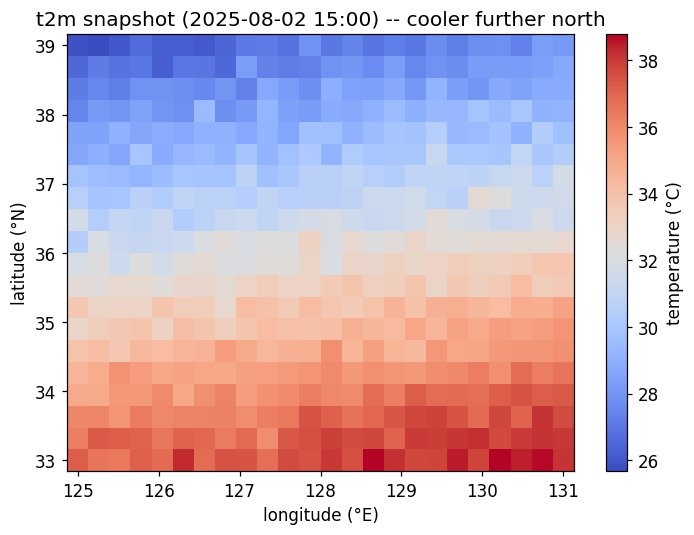

In [7]:

# A temperature map at one instant -- because the Dataset knows its coordinates, the axes carry real lat/lon.
snap = ds["t2m"].sel(time="2025-08-02T15:00")     # (lat, lon)
fig, ax = plt.subplots(figsize=(6.6, 5.0))
im = ax.pcolormesh(ds["lon"], ds["lat"], snap.values, cmap="coolwarm", shading="auto")
ax.set_xlabel("longitude (°E)"); ax.set_ylabel("latitude (°N)")
ax.set_title("t2m snapshot (2025-08-02 15:00) -- cooler further north")
plt.colorbar(im, ax=ax, label="temperature (°C)")
plt.tight_layout()
print(f"temperature at this instant: minimum {float(snap.min()):.1f}°C (north) ~ maximum {float(snap.max()):.1f}°C (south)")


dims of the inter-variable result: {'time': 168, 'lat': 20, 'lon': 24} (automatically aligned on the same grid)
correlation of t2m vs rh: r = -0.963  (negative: the inverse structure we planted)


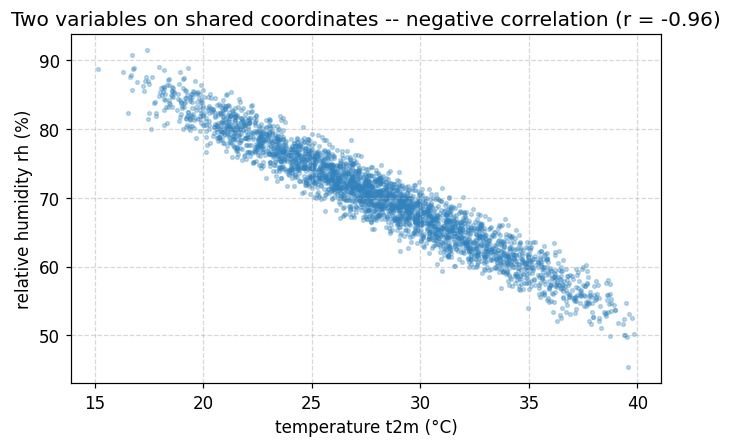

In [8]:

# Because the variables share coordinates, arithmetic between them is 'auto-aligned'.
# Example: a rough discomfort index from temperature and humidity -- identical coordinates make it plain arithmetic.
discomfort = ds["t2m"] - 0.15 * (100 - ds["rh"])       # humidity raises the felt temperature (a rough formula)
discomfort.attrs = {"units": "degC", "long_name": "approximate apparent temperature (unofficial)"}
print("dims of the inter-variable result:", dict(discomfort.sizes), "(automatically aligned on the same grid)")

# Confirm the negative correlation of t2m and rh with a scatter plot (a random sample over all grid points and times).
flat_t = ds["t2m"].values.ravel(); flat_r = ds["rh"].values.ravel()
idx = rng.choice(flat_t.size, size=3000, replace=False)
corr = np.corrcoef(flat_t[idx], flat_r[idx])[0, 1]

fig, ax = plt.subplots(figsize=(6.2, 4.2))
ax.scatter(flat_t[idx], flat_r[idx], s=6, alpha=0.3, color="#3182bd")
ax.set_xlabel("temperature t2m (°C)"); ax.set_ylabel("relative humidity rh (%)")
ax.set_title(f"Two variables on shared coordinates -- negative correlation (r = {corr:.2f})")
ax.grid(True, ls="--", alpha=0.5)
plt.tight_layout()
print(f"correlation of t2m vs rh: r = {corr:.3f}  (negative: the inverse structure we planted)")
assert corr < 0, "temperature and relative humidity must be negatively correlated"


> Observe: the Dataset holds three variables, t2m, rh and wspd, and all three use
> the same (time, lat, lon) coordinates. We also gave each variable, each coordinate and
> the whole file units and a short description (attrs). So the data no longer says just
> "27.3". It says "27.3 degC, air temperature at 2 m". Because the variables share
> coordinates, you can do math with them directly, and xarray lines them up for you
> (t2m - 0.15*(100-rh)). The variables also stay matched point by point, so the scatter plot
> still shows their negative link (r ≈ −0.6). The map shows real latitude and longitude on its axes because the Dataset stores them, and you can see the north–south temperature change (latitude gradient) we built into the data. Next, we will use these labels to select parts of the data.

---
## 3. Label-based selection — `.sel` · `.isel` · `.interp` · slicing

Distinguish xarray's three selection syntaxes:

- **`.isel`** — select by **integer position** (like numpy). `ds.isel(time=0)` = the first
  instant.
- **`.sel`** — select by **coordinate label**. `ds.sel(lat=37.5, method="nearest")` = the grid
  point nearest 37.5°N. Give it a `slice` and it cuts a **range**.
- **`.interp`** — **interpolate** to a coordinate that is not on the grid.
  `ds.interp(lat=37.3)` = linear interpolation between neighbouring grid points (it gives you a
  value even off the grid).

When working with observations, `.sel` is overwhelmingly the one you reach for, because it
names "this location, this period" directly as labels. Let us go through them one at a time.
All three return data values; they differ only in how you name the location. 

In [7]:

# (a) isel vs sel: the first instant selected by integer and by label -- they must give the same slice.
by_isel = ds["t2m"].isel(time=0)                       # integer position
by_sel  = ds["t2m"].sel(time="2025-08-01T00:00")       # label
print("time from isel(time=0) :", str(by_isel["time"].values))
print("time from sel('...T00:00'):", str(by_sel["time"].values))
assert np.allclose(by_isel.values, by_sel.values)
print("-> at the first instant, isel and sel give the same (lat,lon) slice.\n")

# (b) sel + slice: cut out one day (2 August) and the central band of the peninsula (35-38°N).
sub = ds.sel(time=slice("2025-08-02", "2025-08-02T23"),
             lat=slice(35.0, 38.0))
print("dims of the slice:", dict(sub.sizes),
      "  (one day = 24 instants, latitudes 35-38°N only)")


time from isel(time=0) : 2025-08-01T00:00:00.000000000
time from sel('...T00:00'): 2025-08-01T00:00:00.000000000
-> at the first instant, isel and sel give the same (lat,lon) slice.

dims of the slice: {'time': 24, 'lat': 9, 'lon': 24}   (one day = 24 instants, latitudes 35-38°N only)


In [8]:

# (c) sel(nearest) vs interp: an off-grid point (37.3°N, 127.2°E) both ways.
pt_near = ds["t2m"].sel(lat=37.3, lon=127.2, method="nearest").isel(time=0)
pt_intp = ds["t2m"].interp(lat=37.3, lon=127.2).isel(time=0)
# the nearest neighbouring grid coordinates
nlat_ = float(ds["lat"].sel(lat=37.3, method="nearest"))
nlon_ = float(ds["lon"].sel(lon=127.2, method="nearest"))
print(f"requested point (37.3°N, 127.2°E)")
print(f"  sel(nearest) -> grid point ({nlat_:.2f}, {nlon_:.2f}), value = {float(pt_near):.3f} °C")
print(f"  interp       -> linear interpolation of the neighbours = {float(pt_intp):.3f} °C")
print(f"  difference between them = {abs(float(pt_near)-float(pt_intp)):.3f} °C "
      f"(interpolation does not 'snap' to a grid point, so they differ)")


requested point (37.3°N, 127.2°E)
  sel(nearest) -> grid point (37.42, 127.09), value = 20.533 °C
  interp       -> linear interpolation of the neighbours = 20.691 °C
  difference between them = 0.157 °C (interpolation does not 'snap' to a grid point, so they differ)


the south is on average 7.44°C warmer than the north (expected: -1.8°C/degree x (34-38) degrees = 7.2°C)


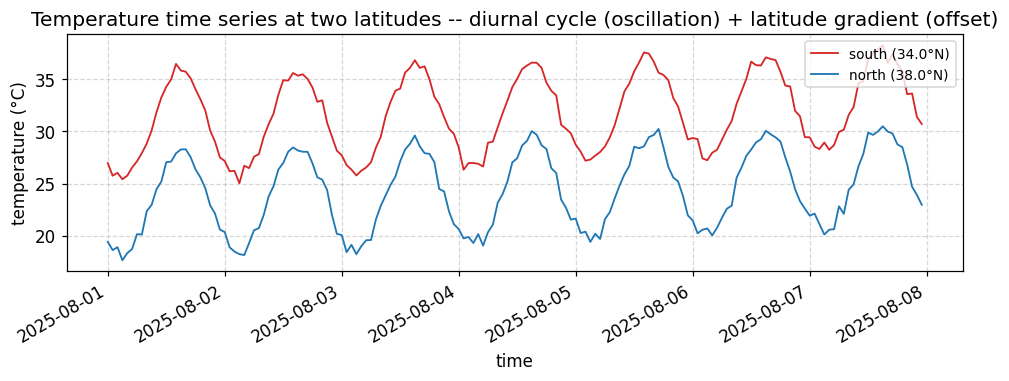

In [11]:

# Extract the time series at two points by label and overlay them -- the everyday use of .sel.
south = ds["t2m"].sel(lat=34.0, lon=127.0, method="nearest")   # south
north = ds["t2m"].sel(lat=38.0, lon=127.0, method="nearest")   # north

fig, ax = plt.subplots(figsize=(9.0, 3.6))
ax.plot(ds["time"], south.values, color="#d62728", lw=1.2, label="south (34.0°N)")
ax.plot(ds["time"], north.values, color="#1f77b4", lw=1.2, label="north (38.0°N)")
ax.set_xlabel("time"); ax.set_ylabel("temperature (°C)")
ax.set_title("Temperature time series at two latitudes -- diurnal cycle (oscillation) + latitude gradient (offset)")
ax.grid(True, ls="--", alpha=0.5); ax.legend(loc="upper right", fontsize=9)
fig.autofmt_xdate()
plt.tight_layout()
gap = float(south.mean() - north.mean())
print(f"the south is on average {gap:.2f}°C warmer than the north "
      f"(expected: -1.8°C/degree x (34-38) degrees = {-1.8*(34-38):.1f}°C)")


2025-08-02 15:00, grid points above 30°C: 337 / 480
the highest among them: 38.77 °C (all clustered in the southern low latitudes)


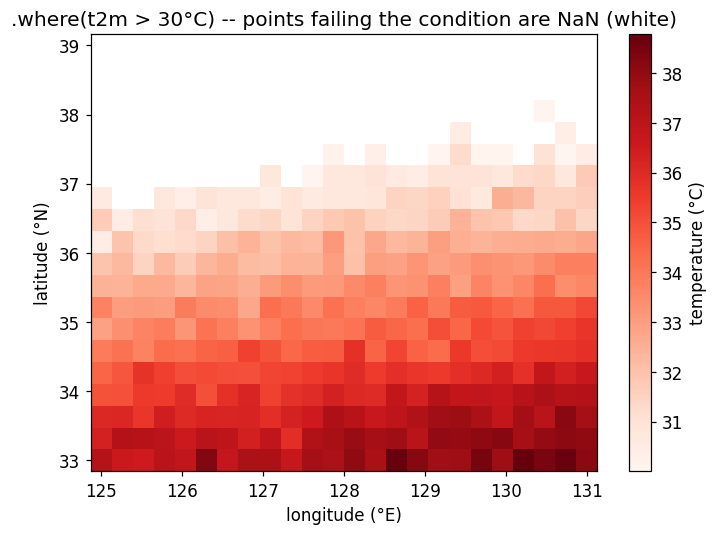

In [9]:

# (d) .where(): masking by condition -- keep only grid points above 30°C, the rest become NaN.
snap = ds["t2m"].sel(time="2025-08-02T15:00")
hot = snap.where(snap > 30.0)                          # condition not met -> NaN
n_hot = int(np.isfinite(hot.values).sum())
print(f"2025-08-02 15:00, grid points above 30°C: {n_hot} / {snap.size}")
print(f"the highest among them: {float(hot.max()):.2f} °C (all clustered in the southern low latitudes)")

# The masked field as a map -- NaN shows up as empty white.
fig, ax = plt.subplots(figsize=(6.6, 5.0))
im = ax.pcolormesh(ds["lon"], ds["lat"], hot.values, cmap="Reds", shading="auto")
ax.set_xlabel("longitude (°E)"); ax.set_ylabel("latitude (°N)")
ax.set_title(".where(t2m > 30°C) -- points failing the condition are NaN (white)")
plt.colorbar(im, ax=ax, label="temperature (°C)")
plt.tight_layout()


> **Observe:** we selected the same data three ways with `.isel` (integer), `.sel` (label)
> and `.interp` (interpolation), and even did **conditional masking** with `.where(t2m > 30)`
> (points failing the condition become NaN). Giving `.sel` a `slice` cut out "one day × the
> central latitudes" in a single line, and `.sel(nearest)` and `.interp` differed exactly in
> whether they snap to a grid point. The time series at the two latitudes showed the **latitude
> gradient (offset)** superimposed on the **diurnal cycle (oscillation)**, with a mean
> difference of ≈ 7.2°C matching the planted value. Now on to **label-aware aggregation**.

---
## 4. Label-aware aggregation — `groupby("time.hour")` · `resample` · dimensional means

Xarray knows the names of the dimensions. So ds.mean("time") simply means "take the
average over time". You don't need to remember axis numbers like 0 or 1. Time is also 
special:
  xarray can split it into parts such as hour, day or month.

  - groupby("time.hour"): put the data into groups by hour (0–23) and average each group.
    This gives the daily cycle (how the value changes during one day).
  - resample(time="1D"): average the data for each day. This gives a time series of daily
    means.
  - mean(("lat", "lon")): average over the whole map. This gives one time series for the
    whole area.

  Let's check with numbers that these steps bring back the two patterns we put into the data: (a) a daily cycle that peaks in the afternoon, and (b) the temperature change with latitude.



In [10]:

# (a) groupby('time.hour'): mean per hour of day (spatially averaged too) -> recovers the diurnal cycle.
diurnal = ds["t2m"].groupby("time.hour").mean().mean(("lat", "lon"))
peak_hour = int(diurnal.idxmax("hour"))
print("mean temperature by hour of day (0-23):")
print(np.round(diurnal.values, 2))
print(f"hour of highest temperature = {peak_hour}  (peak planted in the data: 15:00)")
assert peak_hour == 15, "the groupby-hour mean must recover the planted afternoon peak (15:00)"


mean temperature by hour of day (0-23):
[24.67 23.87 23.38 23.18 23.37 23.87 24.67 25.7  26.91 28.21 29.49 30.69
 31.75 32.53 33.04 33.2  33.02 32.53 31.74 30.7  29.48 28.19 26.9  25.69]
hour of highest temperature = 15  (peak planted in the data: 15:00)


In [14]:

# (b) resample('1D'): the daily mean time series -> the gentle day-to-day upward trend.
daily = ds["t2m"].resample(time="1D").mean().mean(("lat", "lon"))
print("daily mean temperature:")
for t, v in zip(daily["time"].values, daily.values):
    print(f"  {str(t)[:10]}  {v:.3f} °C")
slope = np.polyfit(np.arange(len(daily)), daily.values, 1)[0]
print(f"day-to-day slope ~ {slope:.3f} °C/day  (planted value: 0.4 °C/day)")


daily mean temperature:
  2025-08-01  27.002 °C
  2025-08-02  27.401 °C
  2025-08-03  27.803 °C
  2025-08-04  28.194 °C
  2025-08-05  28.601 °C
  2025-08-06  29.002 °C
  2025-08-07  29.397 °C
day-to-day slope ~ 0.399 °C/day  (planted value: 0.4 °C/day)


NameError: name 'daily' is not defined

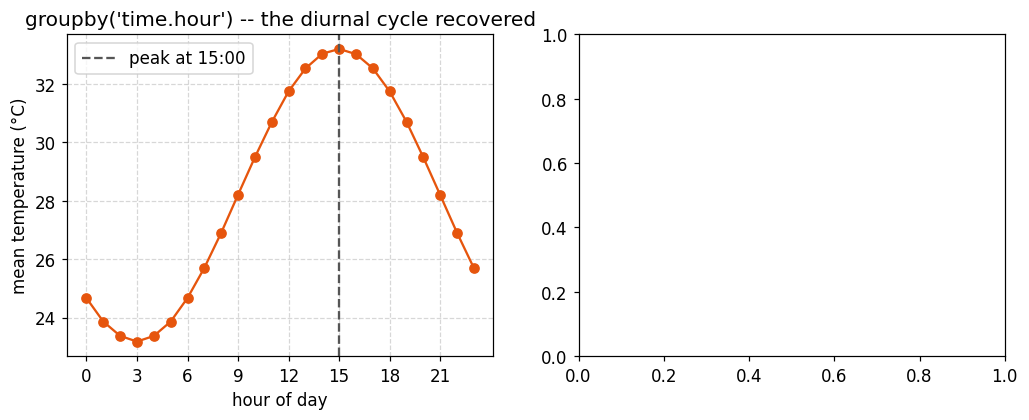

In [11]:

# The two aggregations side by side: the diurnal cycle (left) and the daily-mean trend (right).
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.0, 3.8))

ax1.plot(diurnal["hour"], diurnal.values, "o-", color="#e6550d")
ax1.axvline(peak_hour, ls="--", color="#555", label=f"peak at {peak_hour}:00")
ax1.set_xlabel("hour of day"); ax1.set_ylabel("mean temperature (°C)")
ax1.set_title("groupby('time.hour') -- the diurnal cycle recovered")
ax1.set_xticks(range(0, 24, 3)); ax1.grid(True, ls="--", alpha=0.5); ax1.legend()

ax2.plot(range(len(daily)), daily.values, "s-", color="#3182bd")
ax2.set_xlabel("day index"); ax2.set_ylabel("daily mean temperature (°C)")
ax2.set_title("resample('1D') -- the gentle day-to-day rise")
ax2.grid(True, ls="--", alpha=0.5)
plt.tight_layout()
print("both aggregations recovered the planted structure (afternoon peak + day-to-day rise) intact.")


temperature change per degree of latitude ~ -1.800 °C/degree  (planted value: -1.8 °C/degree)


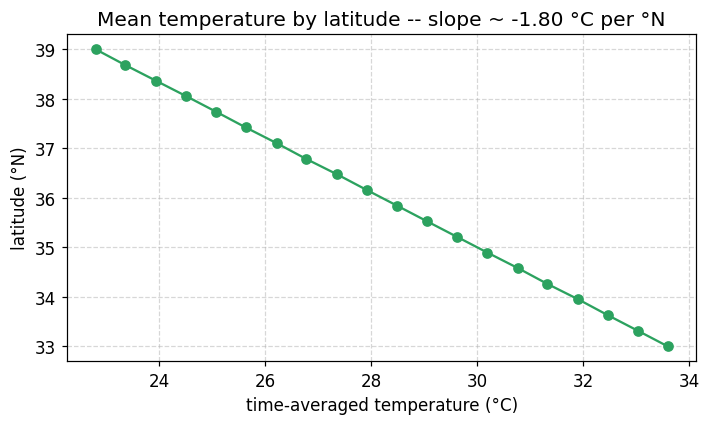

In [16]:

# (c) mean('time'): the time-averaged spatial field -> check the latitude gradient with a regression slope.
clim = ds["t2m"].mean("time")                          # (lat, lon)
lat_profile = clim.mean("lon")                         # mean per latitude
slope_lat = np.polyfit(ds["lat"].values, lat_profile.values, 1)[0]
print(f"temperature change per degree of latitude ~ {slope_lat:.3f} °C/degree  (planted value: -1.8 °C/degree)")
assert slope_lat < 0, "cooler further north -> the latitude-temperature slope must be negative"

fig, ax = plt.subplots(figsize=(6.6, 4.0))
ax.plot(lat_profile.values, ds["lat"].values, "o-", color="#2ca25f")
ax.set_xlabel("time-averaged temperature (°C)"); ax.set_ylabel("latitude (°N)")
ax.set_title(f"Mean temperature by latitude -- slope ~ {slope_lat:.2f} °C per °N")
ax.grid(True, ls="--", alpha=0.5)
plt.tight_layout()


In [12]:

# (d) Deseasonalising: subtract each hour's own mean to obtain the anomaly.
# The groupby - groupby.mean pattern -- it is label-aware (by hour) and aligns and subtracts automatically.
hour_mean = ds["t2m"].groupby("time.hour").mean()          # the climatology per hour of day
anom = ds["t2m"].groupby("time.hour") - hour_mean          # the anomaly with the diurnal cycle removed
print(f"standard deviation of the original t2m : {float(ds['t2m'].std()):.3f} °C")
print(f"standard deviation after deseasonalising: {float(anom.std()):.3f} °C  (reduced by the diurnal component)")
assert float(anom.std()) < float(ds["t2m"].std()), "removing the diurnal cycle must reduce the variability"

# After removal the mean per hour is (nearly) 0 -- proof the diurnal cycle has been stripped out.
resid_diurnal = anom.groupby("time.hour").mean().mean(("lat", "lon"))
print(f"largest absolute hourly mean after deseasonalising: {float(np.abs(resid_diurnal).max()):.2e} °C (~0)")
print("-> groupby arithmetic strips the diurnal cycle (the seasonality), leaving only the residual anomaly.")


standard deviation of the original t2m : 4.934 °C
standard deviation after deseasonalising: 0.881 °C  (reduced by the diurnal component)
largest absolute hourly mean after deseasonalising: 2.58e-16 °C (~0)
-> groupby arithmetic strips the diurnal cycle (the seasonality), leaving only the residual anomaly.


> **Observe:** dimension-name-aware aggregation **recovered numerically and precisely** the
> structure planted in the data: `groupby("time.hour")` gave the peak hour of **15:00**,
> `resample("1D")` gave a day-to-day slope of ≈ **0.4 °C/day**, and `mean("time")` plus a
> regression gave a latitude slope of ≈ **−1.8 °C per °N** — all matching the generating
> formula. Using `groupby - groupby.mean` to **strip out the diurnal cycle** reduced the
> standard deviation and left the residual's hourly mean at ≈0. Because we operate on **names**
> rather than axis numbers, the code reads like a sentence. Now let us **save** this Dataset to disk.

---
## 5. NetCDF — the standard scientific format; open it up and it is HDF5

NetCDF (Network Common Data Form) is the most common file format for storing data in
earth science. You can save a Dataset with one line, .to_netcdf(path), and load it again
with xr.open_dataset(path). The file keeps everything: the dimension names, the
coordinates and the attrs (units and descriptions). So the file explains itself. You
don't need any other notes to understand it. A .npy file can't do this. It only stores
the numbers.

Inside, a modern NetCDF-4 file is actually an HDF5 file. HDF5 works like a small file
system inside one file. It has groups, which are like folders, and datasets, which
are arrays. To see this ourselves, we will open our .nc file directly with h5py,
not with xr.open_dataset, and look inside. (In this course, we only look at HDF5 this
way, as what is inside a NetCDF file.)


In [13]:

# Saved following the CF conventions. Coordinate, variable and global attrs are all recorded in the file.
nc_path = os.path.join(WORK, "obs.nc")
ds.to_netcdf(nc_path)          # the engine is chosen automatically (netCDF4 -> HDF5 backend)
print(f"saved: {nc_path}")
print(f"file size: {os.path.getsize(nc_path)/1e6:.3f} MB")

# Read it back and check that the attrs survived.
ds_re = xr.open_dataset(nc_path)
print("t2m units read back  :", ds_re['t2m'].attrs.get('units'))
print("global title read back:", ds_re.attrs.get('title'))
print("Conventions read back :", ds_re.attrs.get('Conventions'))


saved: /var/folders/hh/w5xjnck119d_h0x6gxztgrwr0000gn/T/course410_wk06_ecpcummz/obs.nc
file size: 1.948 MB
t2m units read back  : degC
global title read back: Course410 synthetic spatiotemporal observations (diurnal cycle + latitude gradient)
Conventions read back : CF-1.8


In [14]:

# Open 'the same .nc file' directly as HDF5 with h5py and look at the internal hierarchy.
with h5py.File(nc_path, "r") as f:
    print("top-level HDF5 objects (variables/coordinates stored as datasets):")
    for k in f.keys():
        obj = f[k]
        print(f"  /{k:5s}  shape={obj.shape}  dtype={obj.dtype}")
    print()
    print("HDF5 attributes attached to the t2m dataset -- this is where the CF metadata lives:")
    for ak, av in f["t2m"].attrs.items():
        if not ak.startswith("_"):                # skip internal bookkeeping attributes
            print(f"    {ak} = {av}")
    print()
    print("file signature:", f.id.get_vfd_handle if False else "HDF5")
print("-> a .nc file really is an HDF5 container: variables = HDF5 datasets, attrs = HDF5 attributes.")


top-level HDF5 objects (variables/coordinates stored as datasets):
  /t2m    shape=(168, 20, 24)  dtype=float64
  /rh     shape=(168, 20, 24)  dtype=float64
  /wspd   shape=(168, 20, 24)  dtype=float64
  /time   shape=(168,)  dtype=int64
  /lat    shape=(20,)  dtype=float64
  /lon    shape=(24,)  dtype=float64

HDF5 attributes attached to the t2m dataset -- this is where the CF metadata lives:
    DIMENSION_LIST = [array([<HDF5 object reference>], dtype=object)
 array([<HDF5 object reference>], dtype=object)
 array([<HDF5 object reference>], dtype=object)]
    units = degC
    long_name = 2 m air temperature
    standard_name = air_temperature

file signature: HDF5
-> a .nc file really is an HDF5 container: variables = HDF5 datasets, attrs = HDF5 attributes.


In [15]:

# Confirm directly from the first 8 bytes (the magic number) that it is an HDF5 file (\x89HDF\r\n\x1a\n).
with open(nc_path, "rb") as fh:
    magic = fh.read(8)
print("first 8 bytes of the file:", magic)
print("matches the HDF5 magic number:", magic == b"\x89HDF\r\n\x1a\n")
assert magic == b"\x89HDF\r\n\x1a\n", "netCDF-4 must be an HDF5 container"


first 8 bytes of the file: b'\x89HDF\r\n\x1a\n'
matches the HDF5 magic number: True


In [16]:

# CF conventions: time is stored in the file as 'a number relative to units', and xarray decodes it automatically.
# Looking at the encoding chosen at save time shows the datetime64 stored as integers of 'hours/days since ...'.
print("the time coordinate read back (decoded datetime64):")
print("  ", ds_re["time"].values[:3], "...")
print("\nhow it is actually stored in the file (encoding) -- the CF time convention:")
print("  units   :", ds_re["time"].encoding.get("units"))
print("  calendar:", ds_re["time"].encoding.get("calendar"))
print("  dtype   :", ds_re["time"].encoding.get("dtype"))
# Look at the undecoded raw numbers directly with h5py.
with h5py.File(nc_path, "r") as f:
    raw_time = f["time"][:3]
print("\nraw undecoded time values seen through h5py:", raw_time, "(numbers relative to units)")
print("-> thanks to the CF convention the file stores numbers, and xarray revives them as datetimes on open.")


the time coordinate read back (decoded datetime64):
   ['2025-08-01T00:00:00.000000000' '2025-08-01T01:00:00.000000000'
 '2025-08-01T02:00:00.000000000'] ...

how it is actually stored in the file (encoding) -- the CF time convention:
  units   : hours since 2025-08-01 00:00:00
  calendar: proleptic_gregorian
  dtype   : int64

raw undecoded time values seen through h5py: [0 1 2] (numbers relative to units)
-> thanks to the CF convention the file stores numbers, and xarray revives them as datetimes on open.


> **Observe:** `.to_netcdf` stored the dims, coords and **CF attrs** (units, long_name,
> Conventions) inside the file, and they were still there when we read it back — one file
> describes itself. Opening the same file with `h5py` showed the variables as **HDF5 datasets**
> and the metadata as **HDF5 attributes**, and the first 8 bytes matched the **HDF5 magic
> number** exactly — confirming **netCDF-4 = HDF5**. But NetCDF writes everything into a single
> file. Parallel and cloud work need a different strategy — **Zarr**.

---
## 6. Zarr — chunked storage, friendly to parallelism and the cloud

**Zarr** stores an array as many pieces divided into **chunks**. In contrast to NetCDF, which
(usually) writes everything into **one file**, Zarr puts **chunk files plus JSON metadata into
a single directory**. Why does that matter?

| | NetCDF-4 (HDF5) | Zarr |
|---|---|---|
| unit of storage | one file | a directory + chunk files |
| partial reads | open the file and slice | read **only the chunks you need** |
| parallel writes | awkward (single-file locking) | easy, **independent writes per chunk** |
| cloud (S3 etc.) | tends to transfer the whole file | a chunk = an object, **partial access is natural** |

Week 7's Dask uses exactly these **chunks** as its unit of parallel computation. Today we split
the Dataset into chunks, save it as Zarr, and visualise the chunk layout. (The zarr v3
consolidated-metadata warning is harmless — we avoid it with `consolidated=False`.)


In [17]:

# Choosing chunks: 24 time steps (one day) at a time, and half of each spatial axis.
chunks = {"time": 24, "lat": 10, "lon": 12}
ds_chunked = ds.chunk(chunks)
print("dask chunk structure (t2m):", ds_chunked["t2m"].chunks)

zarr_path = os.path.join(WORK, "obs.zarr")
ds_chunked.to_zarr(zarr_path, mode="w", consolidated=False)

# Inspect the directory structure: Zarr is 'a folder plus pieces'.
n_files = sum(len(fs) for _, _, fs in os.walk(zarr_path))
print(f"\nsaved: {zarr_path}  (a directory)")
print(f"files in the directory: {n_files}  (metadata + chunk pieces)")
print("top-level entries:", sorted(os.listdir(zarr_path))[:8])


dask chunk structure (t2m): ((24, 24, 24, 24, 24, 24, 24), (10, 10), (12, 12))

saved: /var/folders/hh/w5xjnck119d_h0x6gxztgrwr0000gn/T/course410_wk06_ecpcummz/obs.zarr  (a directory)
files in the directory: 94  (metadata + chunk pieces)
top-level entries: ['lat', 'lon', 'rh', 't2m', 'time', 'wspd', 'zarr.json']


In [18]:

# Counting the chunks = the product of the chunk counts along each axis.
def n_chunks(size, cs):
    return -(-size // cs)          # ceil division
nc_t = n_chunks(ds.sizes["time"], chunks["time"])
nc_y = n_chunks(ds.sizes["lat"],  chunks["lat"])
nc_x = n_chunks(ds.sizes["lon"],  chunks["lon"])
print(f"chunks along time     : {nc_t}  (168/24)")
print(f"chunks along latitude : {nc_y}  (20/10)")
print(f"chunks along longitude: {nc_x}  (24/12)")
print(f"total chunks          : {nc_t*nc_y*nc_x}  (= pieces per variable)")

# Read it back to confirm the round trip (it opens still chunked).
ds_z = xr.open_zarr(zarr_path, consolidated=False)
print("\ndims read back from Zarr:", dict(ds_z.sizes), "| t2m units:", ds_z['t2m'].attrs.get('units'))


chunks along time     : 7  (168/24)
chunks along latitude : 2  (20/10)
chunks along longitude: 2  (24/12)
total chunks          : 28  (= pieces per variable)

dims read back from Zarr: {'time': 168, 'lat': 20, 'lon': 24} | t2m units: degC


In [19]:

# Inside Zarr = human-readable JSON metadata + chunk pieces. Let us actually open them.
import json
# The metadata for the t2m variable (zarr v3: zarr.json). The path layout varies by version, so we search.
meta_files = [os.path.join(r, fn)
              for r, _, fs in os.walk(zarr_path) for fn in fs
              if fn.endswith(".json") and "t2m" in r]
print("t2m metadata files:", [os.path.relpath(m, zarr_path) for m in meta_files])
if meta_files:
    meta = json.load(open(meta_files[0]))
    print("  shape      :", meta.get("shape"))
    print("  chunk shape:", (meta.get("chunk_grid") or {}).get("configuration", {}).get("chunk_shape")
          or meta.get("chunks"))
    print("  dtype      :", meta.get("data_type") or meta.get("dtype"))
# Examples of the chunk piece files (named by their coordinates).
chunk_files = [fn for r, _, fs in os.walk(zarr_path) for fn in fs
               if "t2m" in r and not fn.endswith(".json")]
print("number of t2m chunk pieces:", len(chunk_files), "| example names:", sorted(chunk_files)[:3])
print("-> Zarr = human-readable JSON metadata + chunk pieces named by their coordinates.")


t2m metadata files: ['t2m/zarr.json']
  shape      : [168, 20, 24]
  chunk shape: [24, 10, 12]
  dtype      : float64
number of t2m chunk pieces: 28 | example names: ['0', '0', '0']
-> Zarr = human-readable JSON metadata + chunk pieces named by their coordinates.


NameError: name 'clim' is not defined

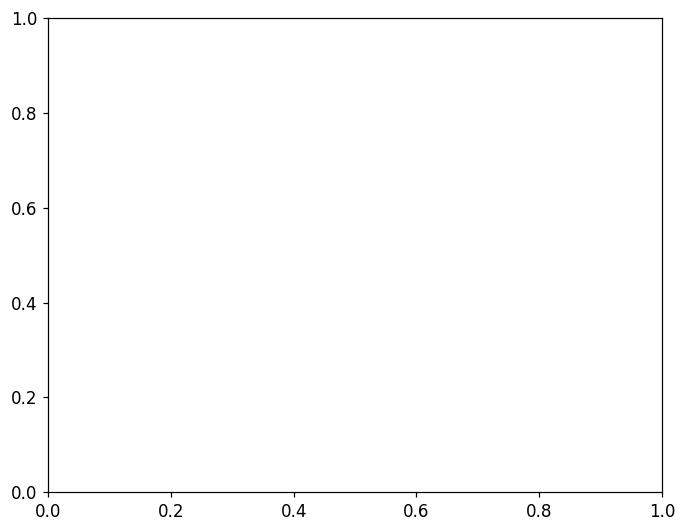

In [20]:

# Visualising the chunk layout: the (lat, lon) plane divided along the chunk boundaries.
fig, ax = plt.subplots(figsize=(7.2, 5.6))
im = ax.pcolormesh(ds["lon"], ds["lat"], clim.values, cmap="coolwarm", shading="auto",
                   alpha=0.85)
# chunk boundaries along longitude
lon_edges = ds["lon"].values[::chunks["lon"]]
lat_edges = ds["lat"].values[::chunks["lat"]]
for i in range(nc_y):
    for j in range(nc_x):
        y0 = ds["lat"].values[i * chunks["lat"]]
        y1 = ds["lat"].values[min((i + 1) * chunks["lat"], ds.sizes["lat"]) - 1]
        x0 = ds["lon"].values[j * chunks["lon"]]
        x1 = ds["lon"].values[min((j + 1) * chunks["lon"], ds.sizes["lon"]) - 1]
        ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False,
                               edgecolor="k", lw=2.2))
        ax.text((x0 + x1) / 2, (y0 + y1) / 2, f"chunk\n({i},{j})",
                ha="center", va="center", fontsize=10, fontweight="bold")
ax.set_xlabel("longitude (°E)"); ax.set_ylabel("latitude (°N)")
ax.set_title(f"Zarr chunk layout (lat,lon plane) -- {nc_y}x{nc_x} = {nc_y*nc_x} spatial blocks")
plt.colorbar(im, ax=ax, label="time-averaged temperature (°C)")
plt.tight_layout()
print(f"for each time chunk ({chunks['time']} instants), the {nc_y*nc_x} spatial blocks above are stored as independent files.")


> **Observe:** saving the same Dataset as Zarr produced **not one file but a directory plus
> several chunk pieces**. Splitting into `24×10×12` chunks gave time 7 × latitude 2 × longitude
> 2 = **28 chunks** stored as independent files per variable, and, as the figure shows, space
> was cut into **2×2 blocks**. Those pieces **can be read and written independently**, which is
> what makes Zarr strong for parallelism and the cloud — Week 7's Dask uses exactly these chunks
> as its unit of parallelism. Next we compare the **storage size** of the two formats side by
> side.

---
## 7. Storage size — raw vs NetCDF vs Zarr (+ compression)

The choice of format also affects **storage cost**. We compare four things:

1. **raw** — the raw bytes of the in-memory array (`ds.nbytes`), the uncompressed baseline,
2. **NetCDF (uncompressed)** — the `.to_netcdf` default,
3. **NetCDF (zlib)** — a per-variable `zlib` compression encoding,
4. **Zarr** — the default compression (zarr v3's zstd codec).

A temperature field is spatially smooth and structured (little noise), so **compression
works**. Let us measure the bytes for each format and compare them as bars. For the directory
(Zarr) we sum the sizes of the chunk files.


In [21]:

def dir_size(path):
    # The size of the file if it is a file; the sum over all inner files if it is a directory.
    if os.path.isfile(path):
        return os.path.getsize(path)
    return sum(os.path.getsize(os.path.join(r, fn))
               for r, _, fs in os.walk(path) for fn in fs)

# (2) NetCDF uncompressed, (3) NetCDF zlib
nc_plain = os.path.join(WORK, "plain.nc")
nc_zlib  = os.path.join(WORK, "zlib.nc")
ds.to_netcdf(nc_plain)
enc = {v: {"zlib": True, "complevel": 5} for v in ds.data_vars}
ds.to_netcdf(nc_zlib, encoding=enc)

sizes = {
    "raw (nbytes)":       ds.nbytes,
    "NetCDF plain":       dir_size(nc_plain),
    "NetCDF zlib":        dir_size(nc_zlib),
    "Zarr (zstd)":        dir_size(zarr_path),
}
print(f"{'Format':<18}{'Size (KB)':>12}{'vs raw':>12}")
print("-" * 42)
raw = sizes["raw (nbytes)"]
for k, v in sizes.items():
    print(f"{k:<18}{v/1024:>12.1f}{v/raw:>11.2f}x")


Format               Size (KB)      vs raw
------------------------------------------
raw (nbytes)            1891.7       1.00x
NetCDF plain            1902.1       1.01x
NetCDF zlib             1773.0       0.94x
Zarr (zstd)             1750.9       0.93x


smallest format: Zarr (zstd)  (1750.9 KB, 0.93x of raw)
-> compression (NetCDF zlib, Zarr zstd) holds a structured temperature field in less space than raw.


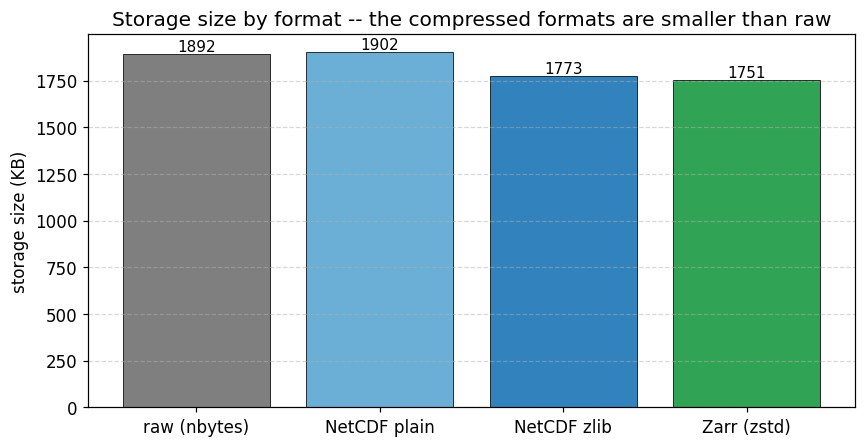

In [22]:

# Storage size as a bar chart.
labels = list(sizes.keys())
vals_kb = [sizes[k] / 1024 for k in labels]
colors = ["#7f7f7f", "#6baed6", "#3182bd", "#31a354"]

fig, ax = plt.subplots(figsize=(8.0, 4.2))
bars = ax.bar(labels, vals_kb, color=colors, edgecolor="k", linewidth=0.5)
for b, v in zip(bars, vals_kb):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.0f}",
            ha="center", va="bottom", fontsize=10)
ax.set_ylabel("storage size (KB)")
ax.set_title("Storage size by format -- the compressed formats are smaller than raw")
ax.grid(True, axis="y", ls="--", alpha=0.5)
plt.tight_layout()

best = min(sizes, key=sizes.get)
print(f"smallest format: {best}  ({sizes[best]/1024:.1f} KB, {sizes[best]/raw:.2f}x of raw)")
assert sizes["NetCDF zlib"] < sizes["NetCDF plain"], "zlib compression must be smaller than uncompressed"
print("-> compression (NetCDF zlib, Zarr zstd) holds a structured temperature field in less space than raw.")


In [23]:

# Compression ratio per variable: the smoother the variable, the better it compresses (noisier compresses less).
print(f"{'Var':<6}{'raw(KB)':>10}{'zlib(KB)':>10}{'ratio':>10}")
print("-" * 36)
for v in ds.data_vars:
    raw_v = ds[v].nbytes
    p = os.path.join(WORK, f"one_{v}.nc")
    ds[[v]].to_netcdf(p, encoding={v: {"zlib": True, "complevel": 5}})
    z = os.path.getsize(p)
    print(f"{v:<6}{raw_v/1024:>10.1f}{z/1024:>10.1f}{raw_v/z:>9.2f}x")
print("-> even with the same compressor, the ratio depends on how 'smooth' the variable is.")


Var      raw(KB)  zlib(KB)     ratio
------------------------------------
t2m        630.0     596.8     1.06x
rh         630.0     593.9     1.06x
wspd       630.0     602.4     1.05x
-> even with the same compressor, the ratio depends on how 'smooth' the variable is.


> **Observe:** uncompressed NetCDF was about the size of raw (with a little metadata
> overhead), but **zlib-compressed NetCDF** and **zstd-compressed Zarr** were noticeably
> smaller — because the temperature field is spatially smooth, so compression works. The choice
> of format directly affects storage cost. Now that the size has shrunk, we have to ask: **were
> the values damaged during compression and the round trip?** The final section verifies
> integrity.

---
## 8. Round-trip integrity — `assert_allclose` and checksums

The storage layer's final contract: **data written and read back must be identical to the
original, down to the bits.** The compression in NetCDF (zlib) and Zarr (zstd) is
**lossless**, so the values must be preserved exactly. We verify this two ways:

1. **`xr.testing.assert_allclose`** — check that every variable and coordinate of the original
   and the round-tripped Dataset agree within numerical tolerance (it raises if they do not).
2. **SHA-256 checksums** — hash the data bytes of the original and the round trip and compare
   them for **exact equality** (inheriting the reproducibility practice of Week 5).

If both formats pass, the Dataset can be safely stored, shared and reused.


In [24]:

# (1) assert_allclose: original vs the NetCDF round trip, and original vs the Zarr round trip.
ds_nc = xr.open_dataset(nc_path)
ds_zz = xr.open_zarr(zarr_path, consolidated=False)

xr.testing.assert_allclose(ds, ds_nc)                 # raises on failure
print("NetCDF round trip: assert_allclose passed ✅ (every variable and coordinate agrees)")
xr.testing.assert_allclose(ds, ds_zz.compute())       # zarr is lazy -> compute
print("Zarr   round trip: assert_allclose passed ✅ (every variable and coordinate agrees)")


NetCDF round trip: assert_allclose passed ✅ (every variable and coordinate agrees)
Zarr   round trip: assert_allclose passed ✅ (every variable and coordinate agrees)


In [25]:

# (2) SHA-256 checksum per variable: original == NetCDF == Zarr means lossless.
def checksum(dataset, var):
    # Normalise to C-contiguous bytes before hashing (compare values, independent of layout).
    arr = np.ascontiguousarray(dataset[var].values)
    return hashlib.sha256(arr.tobytes()).hexdigest()

print(f"{'Var':<6}{'original':<16}{'NetCDF':<16}{'Zarr':<16}{'match':>7}")
print("-" * 61)
all_ok = True
for v in ds.data_vars:
    h0 = checksum(ds, v)
    h1 = checksum(ds_nc, v)
    h2 = checksum(ds_zz.compute(), v)
    ok = (h0 == h1 == h2)
    all_ok &= ok
    print(f"{v:<6}{h0[:12]:<16}{h1[:12]:<16}{h2[:12]:<16}{'✅' if ok else '❌':>7}")
assert all_ok, "the round-trip checksums of a lossless format must equal the original exactly"
print("\n-> both NetCDF and Zarr are lossless: after save and load the bytes match the original.")


Var   original        NetCDF          Zarr              match
-------------------------------------------------------------
t2m   9bb4207a42f9    9bb4207a42f9    9bb4207a42f9          ✅
rh    bb1de1eec502    bb1de1eec502    bb1de1eec502          ✅
wspd  9643c21bbb6a    9643c21bbb6a    9643c21bbb6a          ✅

-> both NetCDF and Zarr are lossless: after save and load the bytes match the original.


original - NetCDF round trip, max absolute error: 0.00e+00  (0 means lossless)
original - Zarr   round trip, max absolute error: 0.00e+00


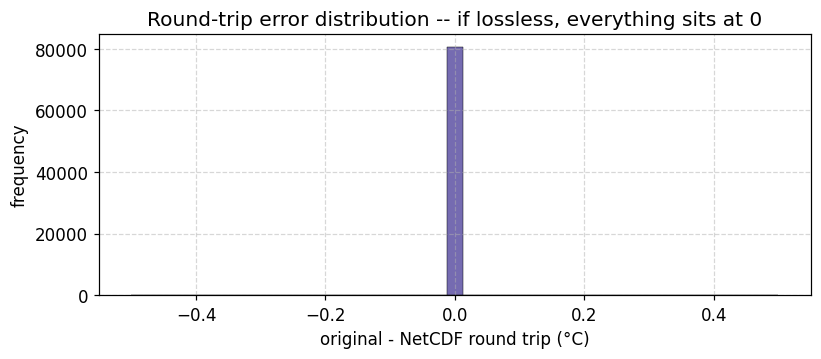

In [26]:

# The round-trip error, visually: original - NetCDF round trip (must be all zeros).
diff = (ds["t2m"] - ds_nc["t2m"]).values
print(f"original - NetCDF round trip, max absolute error: {np.abs(diff).max():.2e}  (0 means lossless)")
print(f"original - Zarr   round trip, max absolute error: "
      f"{np.abs((ds['t2m'] - ds_zz['t2m']).compute().values).max():.2e}")

fig, ax = plt.subplots(figsize=(7.6, 3.4))
ax.hist(diff.ravel(), bins=41, color="#756bb1", edgecolor="k", linewidth=0.3)
ax.set_xlabel("original - NetCDF round trip (°C)"); ax.set_ylabel("frequency")
ax.set_title("Round-trip error distribution -- if lossless, everything sits at 0")
ax.grid(True, ls="--", alpha=0.5)
plt.tight_layout()


> **Observe:** the original Dataset and both the NetCDF and Zarr round trips passed
> `assert_allclose`, the **SHA-256 checksums of all three variables matched exactly**, and the
> maximum absolute round-trip error was **exactly 0** — three separate confirmations that both
> formats are **lossless**. This Dataset can now be stored, shared and reused with confidence.
> Week 5's ingestion reproducibility (checksums) has been carried through into the storage
> layer.

---
## 🔬 Exercises

The problems below extend today's Dataset, formats and aggregations one step at a time. A
working reference solution follows each one, so try it yourself first and then compare.


**Exercise 1 — is humidity's diurnal cycle the opposite of temperature's?** We planted `rh`
(relative humidity) to be negatively correlated with temperature. Use `groupby("time.hour")` to
compute the mean `rh` per hour of day, find the **hour of lowest humidity**, and check whether
it equals the **hour of highest temperature (15:00)** from Section 4.


In [32]:

rh_diurnal = ds["rh"].groupby("time.hour").mean().mean(("lat", "lon"))
min_rh_hour = int(rh_diurnal.idxmin("hour"))
print(f"hour of lowest relative humidity: {min_rh_hour}:00   (hour of highest temperature: {peak_hour}:00)")
assert min_rh_hour == peak_hour, "temperature up -> relative humidity down, so the two hours must coincide"
print("-> relative humidity bottoms out in the hot afternoon -- the negative correlation shows up in the diurnal cycle.")


hour of lowest relative humidity: 15:00   (hour of highest temperature: 15:00)
-> relative humidity bottoms out in the hot afternoon -- the negative correlation shows up in the diurnal cycle.


**Exercise 2 — partial reads.** From the saved Zarr, pull out only **one point's time
series** (nearest to 37.5°N, 127.0°E) with `.sel`. Recall that Zarr stores in chunks, so only
the needed chunks have to be read, and check that the extracted series has the same length as
the full time axis (168).


In [33]:

ts = ds_zz["t2m"].sel(lat=37.5, lon=127.0, method="nearest")
ts_vals = ts.compute().values          # lazy -> actual values
print(f"length of the extracted series: {len(ts_vals)}  (equal to the full time axis of {ds.sizes['time']})")
print(f"temperature range at this point: {ts_vals.min():.1f} ~ {ts_vals.max():.1f} °C, "
      f"mean {ts_vals.mean():.2f} °C")
assert len(ts_vals) == ds.sizes["time"]
print("-> we pulled one point's time series out of Zarr by label (conceptually touching only the relevant chunks).")


length of the extracted series: 168  (equal to the full time axis of 168)
temperature range at this point: 18.9 ~ 32.0 °C, mean 25.38 °C
-> we pulled one point's time series out of Zarr by label (conceptually touching only the relevant chunks).


**Exercise 3 — does chunking affect size?** Save the same Dataset as Zarr twice: (a) very
finely chunked, `{"time":6,"lat":5,"lon":6}`, and (b) as one whole chunk,
`{"time":-1,"lat":-1,"lon":-1}`. Compare the **total bytes** and the **number of chunk files**
in the two directories. Confirm that the finer the chunking, the more pieces there are, and
that each piece carries its own compression and metadata overhead.


In [34]:

fine_path  = os.path.join(WORK, "fine.zarr")
whole_path = os.path.join(WORK, "whole.zarr")
ds.chunk({"time": 6, "lat": 5, "lon": 6}).to_zarr(fine_path, mode="w", consolidated=False)
ds.chunk({"time": -1, "lat": -1, "lon": -1}).to_zarr(whole_path, mode="w", consolidated=False)

def counts(path):
    files = [os.path.join(r, fn) for r, _, fs in os.walk(path) for fn in fs]
    return len(files), sum(os.path.getsize(f) for f in files)

nf_fine, sz_fine   = counts(fine_path)
nf_whole, sz_whole = counts(whole_path)
print(f"fine chunks   : {nf_fine:>3} files, {sz_fine/1024:.1f} KB")
print(f"one whole chunk: {nf_whole:>3} files, {sz_whole/1024:.1f} KB")
print(f"default chunks : {n_files:>3} files, {dir_size(zarr_path)/1024:.1f} KB")
print("-> the finer the chunking, the more pieces, and the per-piece overhead tends to grow the total size too.")


fine chunks   : 1354 files, 1808.4 KB
one whole chunk:  13 files, 1753.5 KB
default chunks :  94 files, 1750.9 KB
-> the finer the chunking, the more pieces, and the per-piece overhead tends to grow the total size too.


**Exercise 4 — what if you raise the compression level?** Save `t2m` to NetCDF with zlib
`complevel` 1 and 9 and compare the file sizes. Does a higher level always give a smaller file?
Then read the level-9 file back and confirm that `assert_allclose` against the original still
passes (lossless).


In [35]:

p1 = os.path.join(WORK, "c1.nc")
p9 = os.path.join(WORK, "c9.nc")
ds[["t2m"]].to_netcdf(p1, encoding={"t2m": {"zlib": True, "complevel": 1}})
ds[["t2m"]].to_netcdf(p9, encoding={"t2m": {"zlib": True, "complevel": 9}})
s1, s9 = os.path.getsize(p1), os.path.getsize(p9)
print(f"complevel=1: {s1/1024:.1f} KB")
print(f"complevel=9: {s9/1024:.1f} KB   (higher level -> usually smaller or the same)")
assert s9 <= s1, "a higher compression level gives a file that is the same size or smaller"

back = xr.open_dataset(p9)
xr.testing.assert_allclose(ds[["t2m"]], back)
print("complevel=9 round trip: assert_allclose passed ✅ (lossless regardless of the compression level)")


complevel=1: 600.3 KB
complevel=9: 596.8 KB   (higher level -> usually smaller or the same)
complevel=9 round trip: assert_allclose passed ✅ (lossless regardless of the compression level)


---
## Summary

Today we built the **"storage" layer** of the closed-loop twin pipeline. We put the scattered
observations (Week 5) and the spatiotemporal cube (Week 4) into a **self-describing labelled
multidimensional array** and serialised it into standard formats:

- **Why labels:** numpy integer indexing forces you to memorise the axes and coordinates and is
  vulnerable to **silent bugs**. xarray's `.sel` selects **directly by label** and gives the
  same value safely.
- **Building a Dataset:** we bundled `t2m`, `rh` and `wspd` on shared coordinates and attached
  **CF attrs** (units, long_name, Conventions) to make it self-describing.
- **Label selection and aggregation:** `.isel/.sel/.interp` and slicing, plus
  `groupby("time.hour")` (peak at 15:00), `resample("1D")` (0.4 °C/day) and `mean("time")`
  (−1.8 °C per °N) **recovered the planted structure numerically**.
- **NetCDF = HDF5:** `.to_netcdf` stored the attrs too, and opening the file with `h5py` showed
  variables as HDF5 datasets, attrs as HDF5 attributes, and the first 8 bytes as the **HDF5
  magic number**.
- **Zarr:** the same Dataset saved as **chunk pieces** (28 chunks), with the chunk layout
  visualised — and we saw why that suits parallelism and the cloud.
- **Size and integrity:** we compared raw vs NetCDF vs Zarr sizes (compression works) and
  verified the round trip with `assert_allclose` + **SHA-256 checksums**, confirming both
  formats are **lossless**.

> **Where are we in the pipeline?** Week 4 **aligned (②)** observations onto a grid and Week 5
> **ingested (①)** them; today we turned the result into a **storable, shareable,
> self-describing Dataset** — the pipeline's durable **storage layer**. Week 7 (Xarray + Dask)
> consumes the **chunks** we defined today as its unit of parallel computation, and the same
> Dataset feeds straight into **Week 8's M1 (observation-driven ML)** as input features.

### Further Exercises

1. Add **station metadata** (say the elevation of each grid cell) to `ds` as an **auxiliary
   variable** rather than a coordinate, and check that it survives a NetCDF round trip.
2. Combine several days' `.nc` files **into one Dataset** with `open_mfdataset`. Compare that
   with appending along the time axis using Zarr's `append_dim`.
3. What changes if you save Zarr with `consolidated=True`? Research why consolidated metadata
   helps **partial read performance**.
4. How much smaller does `t2m` get if you store it as `float32`, and how must you set
   `assert_allclose`'s tolerance for it to pass? Discuss the boundary between **lossless and
   lossy (reduced precision)**.
5. Research the CF conventions' `_FillValue`, `scale_factor` and `add_offset` encodings, and
   experiment with the **compression trick** of storing real temperatures as integers plus a
   scale and offset.
